# 06 · Aprender de EEG de muchos y de pocos votos: ¿un modelo o dos?

**Fases CRISP-DM:** 4 – Modelado (iteración 3) y 5 – Evaluación

La iteración 2 mostró que entrenar solo con EEG de ≥10 votos degrada el desempeño en los de <10 votos
(y que el 93.5 % de los EEG de *Seizure* tienen <10 votos). Hipótesis de trabajo del equipo:
**los EEG de pocos y de muchos votos representan las clases de forma distinta.** Se comparan:

| Enfoque | Idea |
|---|---|
| **A · modelo único** | entrena con todos; Optuna decide cuánto pesa la baja calidad en la pérdida (`lq_weight`) |
| **A' · dos cabezas** | un backbone, una cabeza para alta y otra para baja calidad, y una compuerta que estima de qué tipo es el EEG |
| **B · especialistas** | H (solo ≥10 votos, iteración 2) y L (solo <10 votos), y una regla para elegir cuál usar |

Reglas para elegir especialista ante un caso nuevo: **cascada por confianza** (si H no está seguro, pasa a L, y al revés),
**compuerta aprendida** (estima si el caso "parece" de pocos votos), **mezcla fija** y un **oráculo** que conoce los votos
(no desplegable: en un caso nuevo no se sabe cuántos votos tendría).

**Protocolo:** mismos 5 folds agrupados por paciente; cada predicción viene de un modelo que nunca vio al paciente.
Pesos de ensamble, umbrales y compuertas se ajustan siempre en los otros 4 folds (anidado).
**Objetivo "general"** = promedio de la KL macro en alta y en baja calidad (cada clase y cada grupo pesan igual).

Código: `src/mixed.py`, `src/routing.py`, `run_mixed.sh`.

> **Nota de nomenclatura.** Este notebook pertenece a la **Iteración 2** de CRISP-DM. Las etiquetas internas
> (tablas, CSV y figuras) se generaron antes de ordenar el trabajo por iteraciones: **"fase 1"** = ciclo 2.1,
> **"iteración 2" / "Iter. 2"** = ciclo 2.2 e **"iteración 3"** = ciclo 2.3.


In [1]:
import sys, os, json
sys.path.insert(0, os.path.abspath("../.."))  # raíz del repo (notebooks/iteracion_2/ -> ../..)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from src.config import RESULTS_DIR, FIGURES_DIR, OOF_DIR, TARGETS, CLASSES
from src.viz import set_style, PALETTE, SEQ_CMAP
set_style()
pd.set_option("display.width", 220); pd.set_option("display.max_colwidth", 60)
FIG = FIGURES_DIR / "alta_baja"; FIG.mkdir(exist_ok=True, parents=True)
OPT = RESULTS_DIR / "optuna"
res = pd.read_csv(RESULTS_DIR / "metrics_mixed_comparacion.csv")
conf = pd.read_csv(RESULTS_DIR / "mixed" / "confianza.csv")
rec = pd.read_csv(RESULTS_DIR / "mixed" / "recall_por_clase.csv")
rp = json.load(open(RESULTS_DIR / "mixed" / "routing_params.json"))

## 1. Hiperparámetros encontrados (Optuna, fold 0)

In [2]:
rows = []
for name, desc in [("mix_single_effb0", "A · único B0"), ("mix_single_convnext_t", "A · único ConvNeXt-T"),
                   ("mix_lq_effb0", "B · especialista L, B0")]:
    b = json.load(open(OPT / f"{name}_best.json"))
    t = pd.read_csv(OPT / f"{name}_trials.csv")
    p = b["params"]
    rows.append({"modelo": desc, "intentos": len(t), "podados": int((t.state == "PRUNED").sum()),
                 "objetivo inicial": t.value.iloc[0], "mejor objetivo": b["value"], "lq_weight": p.get("lq_weight", np.nan),
                 "lr": p["lr"], "epochs": p["epochs"], "class_weight": p["class_weight"], "mask_frac": p["mask_frac"],
                 "mixup": p["mixup"]})
pd.DataFrame(rows).round(4)

,modelo,intentos,podados,objetivo inicial,mejor objetivo,lq_weight,lr,epochs,class_weight,mask_frac,mixup
0,A · único B0,16,11,0.6550,0.6478,0.0866,0.0010,12,0.1818,0.2665,0.0637
1,A · único ConvNeXt-T,7,2,0.7133,0.6361,0.3000,0.0001,14,0.8389,0.2072,0.1322
2,"B · especialista L, B0",10,5,0.8902,0.8828,NaN,0.0021,11,0.2123,0.2940,0.2497


El modelo único B0 eligió **`lq_weight` ≈ 0.09**: cada EEG de pocos votos pesa ~1/11 de uno de muchos votos.
Como hay 2.2 veces más EEG de baja calidad, en total aportan ~17 % de la pérdida. En ConvNeXt-T, ninguno de los 7
intentos superó la configuración inicial con `lq_weight` = 0.3 (con tan pocos intentos esa búsqueda es limitada).
Los EEG de pocos votos **sí se usan, pero con un peso bajo**: ayudan como señal adicional, no como verdad.

El especialista ConvNeXt-T de baja calidad no se optimizó (usa los hiperparámetros de la iteración 2, con 10 épocas).

## 2. Tabla comparativa
KL macro: menor es mejor. `frac_a_L`: fracción de casos enviados al especialista de baja calidad.

In [3]:
cols = ["estrategia", "general", "alta_macro_kl", "baja_macro_kl", "alta_kl", "baja_kl", "todas_kl",
        "alta_balanced_accuracy", "baja_balanced_accuracy", "todas_macro_auc", "frac_a_L"]
res[cols].round(3)

,estrategia,general,alta_macro_kl,baja_macro_kl,alta_kl,baja_kl,todas_kl,alta_balanced_accuracy,baja_balanced_accuracy,todas_macro_auc,frac_a_L
0,"Fase 1: ensamble 50/50 (todos, 2 etapas)",0.626,0.423,0.830,0.347,0.681,0.576,0.584,0.606,0.923,NaN
1,Iter. 2: solo alta calidad (ensamble),0.682,0.413,0.950,0.342,0.867,0.701,0.549,0.540,0.901,NaN
2,A: único B0,0.640,0.421,0.859,0.353,0.735,0.614,0.578,0.599,0.913,NaN
3,A: único ConvNeXt-T,0.635,0.463,0.807,0.407,0.681,0.594,0.609,0.646,0.916,NaN
4,"A: único, ensamble optimizado",0.584,0.388,0.780,0.348,0.671,0.569,0.608,0.634,0.922,NaN
5,A': dos cabezas B0 (compuerta interna),0.626,0.448,0.804,0.403,0.688,0.598,0.615,0.634,0.915,NaN
6,A': dos cabezas ConvNeXt-T,0.641,0.479,0.803,0.437,0.682,0.605,0.621,0.657,0.914,NaN
7,"A': dos cabezas, ensamble (compuerta interna)",0.577,0.399,0.755,0.377,0.655,0.567,0.625,0.654,0.923,NaN
8,"A': dos cabezas, cabeza según votos reales (oráculo)",0.567,0.381,0.753,0.318,0.660,0.552,0.577,0.667,0.926,NaN
9,B: solo especialista L (baja),0.639,0.496,0.782,0.487,0.673,0.615,0.615,0.648,0.914,NaN


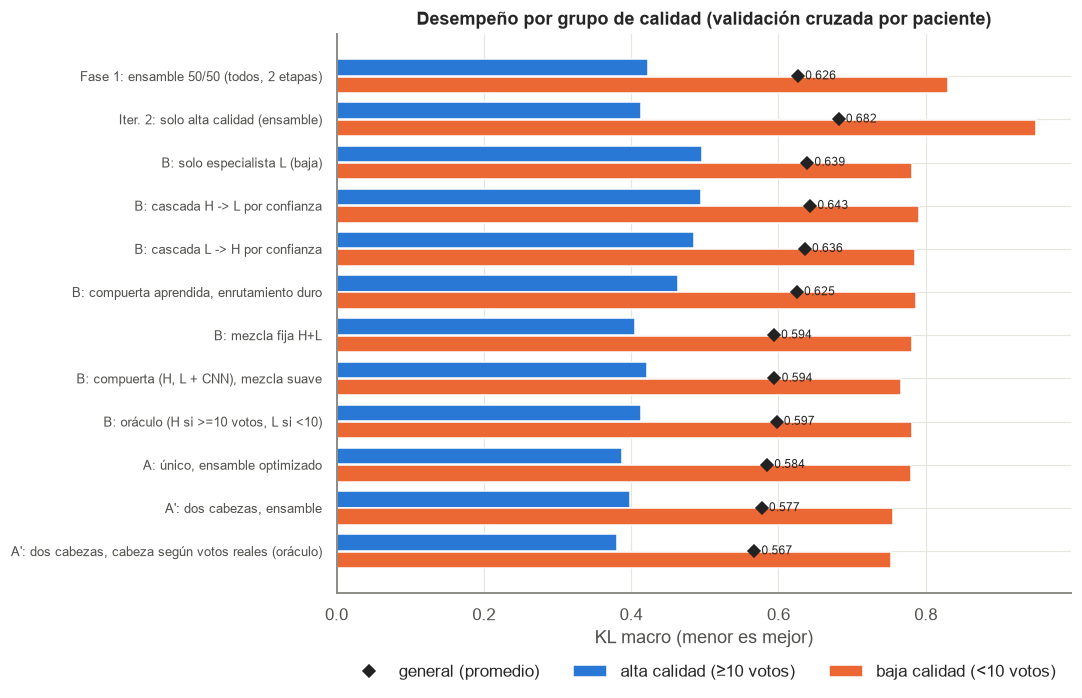

In [4]:
show = ["Fase 1: ensamble 50/50 (todos, 2 etapas)", "Iter. 2: solo alta calidad (ensamble)",
        "B: solo especialista L (baja)", "B: cascada H -> L por confianza", "B: cascada L -> H por confianza",
        "B: compuerta aprendida, enrutamiento duro", "B: mezcla fija H+L", "B: compuerta (H, L + CNN), mezcla suave",
        "B: oráculo (H si >=10 votos, L si <10)", "A: único, ensamble optimizado",
        "A': dos cabezas, ensamble (compuerta interna)", "A': dos cabezas, cabeza según votos reales (oráculo)"]
d = res.set_index("estrategia").loc[show]
fig, ax = plt.subplots(figsize=(10, 6.5))
y = np.arange(len(d))
ax.barh(y - 0.2, d.alta_macro_kl, 0.38, color=PALETTE[0], label="alta calidad (≥10 votos)")
ax.barh(y + 0.2, d.baja_macro_kl, 0.38, color=PALETTE[1], label="baja calidad (<10 votos)")
ax.plot(d.general, y, "D", color="#222222", ms=6, label="general (promedio)")
for i, v in enumerate(d.general):
    ax.text(v + 0.01, i, f"{v:.3f}", va="center", fontsize=8)
ax.set_yticks(y, [s.replace("(compuerta interna)", "").strip() for s in d.index], fontsize=8.5)
ax.invert_yaxis(); ax.set_xlabel("KL macro (menor es mejor)")
ax.set_title("Desempeño por grupo de calidad (validación cruzada por paciente)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=3, frameon=False)
plt.tight_layout(); plt.savefig(FIG / "comparacion_estrategias.png", dpi=130, bbox_inches="tight"); plt.show()

## 3. ¿Son dominios distintos? Prueba cruzada de los especialistas
Cada especialista evaluado en su propio grupo y en el que **no vio**.

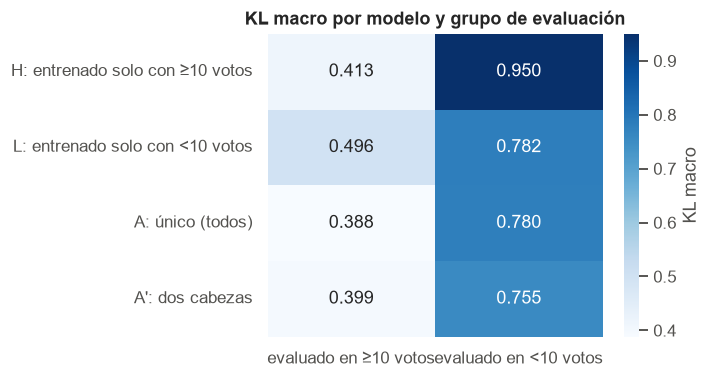

In [5]:
cross = res.set_index("estrategia").loc[
    ["Iter. 2: solo alta calidad (ensamble)", "B: solo especialista L (baja)", "A: único, ensamble optimizado",
     "A': dos cabezas, ensamble (compuerta interna)"], ["alta_macro_kl", "baja_macro_kl"]]
cross.index = ["H: entrenado solo con ≥10 votos", "L: entrenado solo con <10 votos", "A: único (todos)", "A': dos cabezas"]
cross.columns = ["evaluado en ≥10 votos", "evaluado en <10 votos"]
fig, ax = plt.subplots(figsize=(6.5, 3.6))
sns.heatmap(cross, annot=True, fmt=".3f", cmap=SEQ_CMAP, cbar_kws={"label": "KL macro"}, ax=ax)
ax.set_title("KL macro por modelo y grupo de evaluación"); plt.tight_layout()
plt.savefig(FIG / "prueba_cruzada.png", dpi=130, bbox_inches="tight"); plt.show()

## 4. ¿Se puede saber si un caso nuevo es "de pocos votos"? (AUC de la compuerta)
Si la señal no permite distinguir los dos grupos, ninguna regla de enrutamiento puede acercarse al oráculo.

{'compuerta (salidas de H y L)': 0.626, 'compuerta interna del modelo de dos cabezas': 0.65, 'compuerta (salidas de H, L + compuerta CNN)': 0.65}


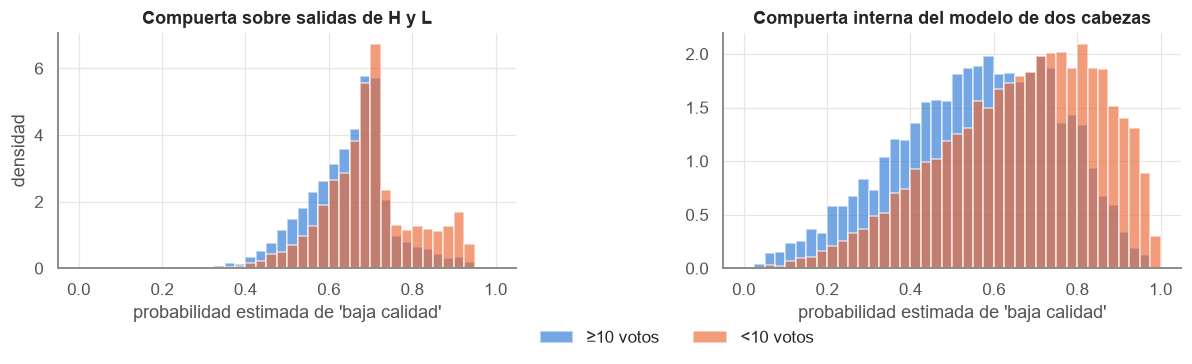

In [6]:
print({k: round(v, 3) for k, v in rp["gate_auc"].items()})
r = pd.read_csv(OOF_DIR / "mixed_routing.csv")
lq = r.total_votes < 10
fig, axs = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, col, title in [(axs[0], "g_compuerta", "Compuerta sobre salidas de H y L"),
                       (axs[1], "g_cnn", "Compuerta interna del modelo de dos cabezas")]:
    bins = np.linspace(0, 1, 41)
    ax.hist(r.loc[~lq, col], bins, alpha=0.65, color=PALETTE[0], density=True, label="≥10 votos")
    ax.hist(r.loc[lq, col], bins, alpha=0.65, color=PALETTE[1], density=True, label="<10 votos")
    ax.set_title(title); ax.set_xlabel("probabilidad estimada de 'baja calidad'")
axs[0].set_ylabel("densidad")
axs[1].legend(loc="upper center", bbox_to_anchor=(-0.1, -0.2), ncol=2, frameon=False)
plt.tight_layout(); plt.savefig(FIG / "compuerta.png", dpi=130, bbox_inches="tight"); plt.show()

## 5. Sobreconfianza: ¿se equivocan los modelos cuando dicen estar seguros?
Para cada modelo y grupo: fracción de casos con confianza ≥0.8 (cobertura) y **tasa de error en esos casos**.
Es el riesgo central de la cascada: un modelo que se equivoca con alta confianza fuera de su dominio no cede el caso.

In [7]:
cm = ["Iter. 2: solo alta calidad (ensamble)", "B: solo especialista L (baja)", "A: único, ensamble optimizado",
      "A': dos cabezas, ensamble (compuerta interna)", "Fase 1: ensamble 50/50 (todos, 2 etapas)"]
c = conf[conf.modelo.isin(cm)].copy()
c[["modelo", "subconjunto", "accuracy", "ece", "cobertura_conf>=0.8", "error_conf>=0.8", "cobertura_conf>=0.9",
   "error_conf>=0.9"]].round(3)

,modelo,subconjunto,accuracy,ece,cobertura_conf>=0.8,error_conf>=0.8,cobertura_conf>=0.9,error_conf>=0.9
0,"Fase 1: ensamble 50/50 (todos, 2 etapas)",alta (>=10),0.738,0.047,0.360,0.059,0.206,0.031
1,"Fase 1: ensamble 50/50 (todos, 2 etapas)",baja (<10),0.708,0.019,0.432,0.104,0.251,0.073
2,Iter. 2: solo alta calidad (ensamble),alta (>=10),0.742,0.137,0.195,0.026,0.064,0.014
3,Iter. 2: solo alta calidad (ensamble),baja (<10),0.634,0.022,0.202,0.133,0.056,0.128
8,"A: único, ensamble optimizado",alta (>=10),0.728,0.114,0.214,0.036,0.075,0.022
9,"A: único, ensamble optimizado",baja (<10),0.718,0.074,0.257,0.072,0.084,0.049
14,"A': dos cabezas, ensamble (compuerta interna)",alta (>=10),0.714,0.104,0.208,0.052,0.071,0.021
15,"A': dos cabezas, ensamble (compuerta interna)",baja (<10),0.726,0.074,0.266,0.064,0.096,0.037
18,B: solo especialista L (baja),alta (>=10),0.660,0.047,0.213,0.092,0.071,0.073
19,B: solo especialista L (baja),baja (<10),0.722,0.063,0.285,0.074,0.105,0.061


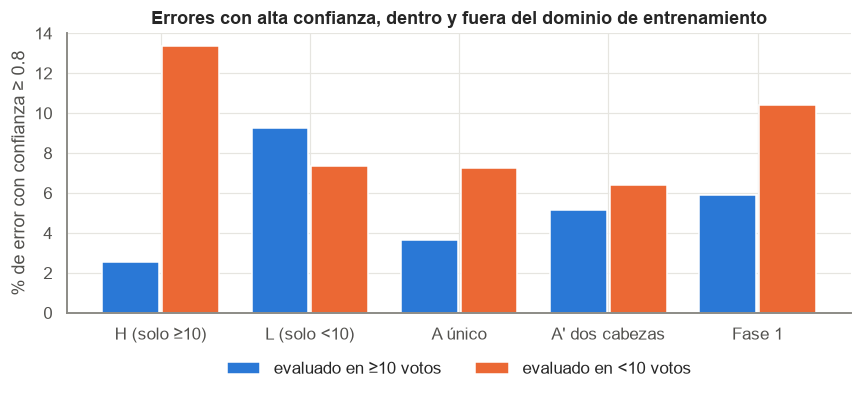

In [8]:
labels = ["H (solo ≥10)", "L (solo <10)", "A único", "A' dos cabezas", "Fase 1"]
piv = c.pivot(index="modelo", columns="subconjunto", values="error_conf>=0.8").loc[cm]
fig, ax = plt.subplots(figsize=(8, 3.8))
x = np.arange(len(cm))
ax.bar(x - 0.2, piv["alta (>=10)"] * 100, 0.38, color=PALETTE[0], label="evaluado en ≥10 votos")
ax.bar(x + 0.2, piv["baja (<10)"] * 100, 0.38, color=PALETTE[1], label="evaluado en <10 votos")
ax.set_xticks(x, labels); ax.set_ylabel("% de error con confianza ≥ 0.8")
ax.set_title("Errores con alta confianza, dentro y fuera del dominio de entrenamiento")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2, frameon=False)
plt.tight_layout(); plt.savefig(FIG / "sobreconfianza.png", dpi=130, bbox_inches="tight"); plt.show()

## 6. Recall por clase y sesgo hacia *Other*

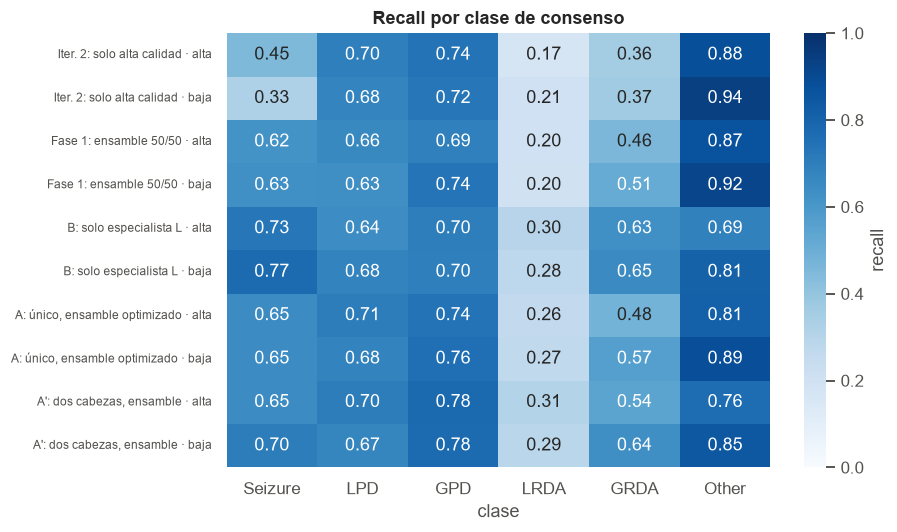

In [9]:
ks = ["Iter. 2: solo alta calidad (ensamble)", "Fase 1: ensamble 50/50 (todos, 2 etapas)", "B: solo especialista L (baja)",
      "A: único, ensamble optimizado", "A': dos cabezas, ensamble (compuerta interna)"]
rr = rec[rec.estrategia.isin(ks)].pivot_table(index=["estrategia", "subconjunto"], columns="clase", values="recall")
rr = rr.reindex(columns=CLASSES).loc[[(k, s) for k in ks for s in ["alta", "baja"]]]
fig, ax = plt.subplots(figsize=(8.5, 5))
sns.heatmap(rr, annot=True, fmt=".2f", cmap=SEQ_CMAP, vmin=0, vmax=1, cbar_kws={"label": "recall"}, ax=ax)
ax.set_yticklabels([f"{a.split('(')[0].strip()} · {b}" for a, b in rr.index], fontsize=8); ax.set_ylabel("")
ax.set_title("Recall por clase de consenso"); plt.tight_layout()
plt.savefig(FIG / "recall_por_clase.png", dpi=130, bbox_inches="tight"); plt.show()

In [10]:
res.set_index("estrategia").loc[ks, ["alta_kappa", "baja_kappa", "alta_min_recall", "baja_min_recall",
                                     "alta_share_pred_other", "alta_share_true_other",
                                     "baja_share_pred_other", "baja_share_true_other"]].round(3)

,alta_kappa,baja_kappa,alta_min_recall,baja_min_recall,alta_share_pred_other,alta_share_true_other,baja_share_pred_other,baja_share_true_other
estrategia,,,,,,,,
Iter. 2: solo alta calidad (ensamble),0.589,0.494,0.168,0.206,0.599,0.529,0.606,0.368
"Fase 1: ensamble 50/50 (todos, 2 etapas)",0.588,0.602,0.204,0.200,0.588,0.529,0.529,0.368
B: solo especialista L (baja),0.523,0.634,0.300,0.278,0.426,0.529,0.401,0.368
"A: único, ensamble optimizado",0.590,0.622,0.264,0.268,0.521,0.529,0.478,0.368
"A': dos cabezas, ensamble (compuerta interna)",0.581,0.637,0.312,0.292,0.480,0.529,0.433,0.368


## 7. Conclusiones

1. **Los dos grupos sí son distintos.** Cada especialista rinde mejor en su propio grupo (H: KL macro 0.413 en ≥10
   votos y 0.950 en <10; L: 0.782 en <10 y 0.496 en ≥10). Los errores con confianza ≥0.8 se multiplican fuera del
   dominio: H pasa de 2.6 % a 13.3 % al evaluarse en EEG de pocos votos.
2. **Pero no hace falta tener dos modelos separados.** El modelo único (A) y el de dos cabezas (A') igualan o superan
   a **cada especialista en su propio terreno**: A' obtiene 0.399 en alta (H: 0.413) y 0.755 en baja (L: 0.782).
   Compartir el backbone le permite aprender de ambos grupos, y la cabeza separada respeta que cada grupo "dibuja"
   las clases de forma distinta.
3. **La cascada por confianza no funciona.** Termina enviando ~95 % de los casos a un solo especialista y queda peor que
   cualquier enfoque A (general 0.636–0.643 frente a 0.577). La confianza no indica si un caso pertenece al dominio,
   justo por la sobreconfianza que el equipo anticipó.
4. **Un caso nuevo solo se reconoce débilmente como "de pocos votos"** (AUC de la compuerta 0.63–0.65). Por eso las reglas
   de enrutamiento duro rinden poco y las mezclas suaves (que no se comprometen con un solo especialista) rinden más.
   El modelo de dos cabezas queda muy cerca de su oráculo (0.577 frente a 0.567): conocer los votos aportaría poco.
5. **Mejor modelo general: A', dos cabezas en ensamble.** General 0.577 (fase 1: 0.626; iteración 2: 0.682), KL simple
   0.567, AUC 0.923, kappa 0.58 / 0.64. Es la estrategia con mayor recall mínimo por clase (0.31 / 0.29), Seizure sube
   a 0.65 / 0.70 (iteración 2: 0.45 / 0.33) y el sesgo hacia *Other* desaparece (predice 48 % frente a 53 % real en alta
   calidad). Si interesa la KL de alta calidad por encima de todo, el modelo único A es el mejor (0.388).
6. **Límites.** La optimización usa solo el fold 0 y pocos intentos en ConvNeXt-T (7). El especialista ConvNeXt-T de baja
   calidad no se optimizó, y el modelo de dos cabezas reutiliza los hiperparámetros del modelo único. LRDA sigue siendo
   la clase más difícil (recall ~0.3).